# Município vs Ajuste Direto

How much of municipal procurement is direct award, by **count** and by **value**?

- **Município:** adjudicante name, accent-folded and lowercased, starts with `municipio` (93 516 rows, 309 NIPC).
- **Ajuste Direto:** `tipo_procedimento` lowercased starts with `ajuste direto` (180 174 rows).

Caveats: 309 NIPCs vs 308 municipalities (at least one false positive); `Câmara Municipal …` is excluded.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl

from base_gov.contracts import is_municipio_expr, load_contracts
from base_gov.entities import (
    canonical_names,
)
from base_gov.stats import MIN_VALUE, filter_min_value, value_impact

DATA = Path("..") / "data"
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_width_chars(140)
plt.rcParams["figure.figsize"] = (10, 4)

In [2]:
contracts_all = load_contracts(DATA / "contracts.parquet")
print(f"rows={contracts_all.height:,}  cols={contracts_all.width}")
# Disregard contracts with |preco_contratual| < MIN_VALUE (€); contracts_all keeps them for before/after comparisons.
contracts = filter_min_value(contracts_all)
print(f"disregarded {contracts_all.height - contracts.height:,} contracts with |preco_contratual| < €{MIN_VALUE:g} "
      f"({(contracts_all.height - contracts.height) / contracts_all.height:.2%}); kept {contracts.height:,}")
print(f"valor_por_dia defined for {contracts['valor_por_dia'].is_not_null().mean():.1%} of kept contracts "
      f"(needs 1 <= prazo_execucao <= 3650 days)")
contracts.head()

rows=409,344  cols=20
disregarded 1,484 contracts with |preco_contratual| < €10 (0.36%); kept 407,860
valor_por_dia defined for 98.9% of kept contracts (needs 1 <= prazo_execucao <= 3650 days)


idcontrato,adjudicante,adjudicante_nipc,adjudicante_name,adjudicante_key,adjudicante_key_source,adjudicatarios,objecto_contrato,preco_contratual,prazo_execucao,data_celebracao,cpv,nuts,ano,tipo_contrato,tipo_procedimento,fundament_ajuste_direto,concorrentes,TipoCriterioAdjudicacao,valor_por_dia
i64,str,str,str,str,str,str,str,f64,i64,date,str,str,i64,str,str,str,str,str,f64
11276556,"""506354490 - Freguesia de Moita…","""506354490""","""Freguesia de Moita dos Ferreir…","""506354490""","""nipc""","""503488356 - Barranca - Socieda…","""AQUISIÇÃO DE TOUT-VENANT""",14300.0,327,2025-02-07,"""14210000-6 - Saibro, areia, br…",null,2025,"""Aquisição de bens móveis""","""Ajuste Direto Regime Geral""",null,null,"""Monofator""",43.730887
11394912,"""513606084 - Águas do Norte, S.…","""513606084""","""Águas do Norte, S. A.""","""513606084""","""nipc""","""513718737 - 4ENERGY - Comércio…","""Aquisição de materiais de inst…",336.24,30,2025-03-24,"""38420000-5 - Instrumentos para…","""PT11D - Douro""",2025,"""Aquisição de bens móveis""","""Ao abrigo de acordo-quadro (ar…",null,null,"""Monofator""",11.208
11382226,"""508094461 - Unidade Local de S…","""508094461""","""Unidade Local de Saúde do Alto…","""508094461""","""nipc""","""500626413 - TECNIMEDE- SOCIEDA…","""Medicamentos""",625.25,1,2025-04-17,"""33000000-0 - Equipamento médic…",null,2025,"""Aquisição de bens móveis""","""Ajuste Direto Regime Geral""",null,null,"""Monofator""",625.25
12794466,"""500745471 - Santa Casa da Mise…","""500745471""","""Santa Casa da Misericórdia de …","""500745471""","""nipc""","""504445960 - MBA PORTUGAL, SA""","""Aquisição de material para a c…",22500.0,730,2025-11-27,"""33169000-2 - Material cirúrgic…",null,2025,"""Aquisição de bens móveis""","""Concurso público""",null,"""515907235-Medarthrex Unipessoa…","""Monofator""",30.821918
11765245,"""508481287 - Unidade Local de S…","""508481287""","""Unidade Local de Saúde de Sant…","""508481287""","""nipc""","""501251685 - ALCON PORTUGAL, LD…","""251G001484/28341-SOLUÇÃO SALIN…",8481.6,123,2025-10-02,"""33690000-3 - Medicamentos vári…",null,2025,"""Aquisição de bens móveis""","""Ajuste Direto Regime Geral""",null,null,"""Monofator""",68.956098


In [3]:
AD_EXPR = pl.col("tipo_procedimento").str.to_lowercase().str.starts_with("ajuste direto")

In [4]:
contracts = contracts.with_columns(
    is_municipio_expr().alias("is_municipio"),
    AD_EXPR.alias("is_ajuste_direto"),
)
print(f"Município: {contracts['is_municipio'].sum():,}  Ajuste Direto: {contracts['is_ajuste_direto'].sum():,}")


Município: 93,331  Ajuste Direto: 179,628


In [5]:
cross = (
    contracts.group_by("is_municipio", "is_ajuste_direto")
    .agg(pl.len().alias("n_contracts"), pl.col("preco_contratual").sum().alias("total_value"))
    .sort("is_municipio", "is_ajuste_direto")
    .with_columns(
        (pl.col("n_contracts") / pl.col("n_contracts").sum().over("is_municipio") * 100).round(1).alias("row_pct_count"),
        (pl.col("total_value") / pl.col("total_value").sum().over("is_municipio") * 100).round(1).alias("row_pct_value"),
        (pl.col("n_contracts") / pl.col("n_contracts").sum().over("is_ajuste_direto") * 100).round(1).alias("col_pct_count"),
    )
)
assert cross["n_contracts"].sum() == contracts.height
for r in cross.iter_rows(named=True):
    print(f"municipio={r['is_municipio']!s:5} ad={r['is_ajuste_direto']!s:5} n={r['n_contracts']:>8,} value=€{r['total_value'] / 1e6:>10,.1f}M")
cross


municipio=False ad=False n= 181,035 value=€  25,153.6M
municipio=False ad=True  n= 133,494 value=€   4,182.8M
municipio=True  ad=False n=  47,197 value=€   7,448.4M
municipio=True  ad=True  n=  46,134 value=€   1,035.1M


is_municipio,is_ajuste_direto,n_contracts,total_value,row_pct_count,row_pct_value,col_pct_count
bool,bool,u32,f64,f64,f64,f64
false,false,181035,2.5154e10,57.6,85.7,79.3
false,true,133494,4.1828e9,42.4,14.3,74.3
true,false,47197,7.4484e9,50.6,87.8,20.7
true,true,46134,1.0351e9,49.4,12.2,25.7


In [6]:
def procedure_mix(df: pl.DataFrame) -> pl.DataFrame:
    return (
        df.group_by("tipo_procedimento")
        .agg(pl.len().alias("n_contracts"), pl.col("preco_contratual").sum().round(2).alias("total_value"))
        .with_columns(
            (pl.col("n_contracts") / pl.col("n_contracts").sum() * 100).round(1).alias("pct_count"),
            (pl.col("total_value") / pl.col("total_value").sum() * 100).round(1).alias("pct_value"),
        )
        .sort("n_contracts", descending=True)
    )


mun = contracts.filter(pl.col("is_municipio"))
rest = contracts.filter(~pl.col("is_municipio"))
mun_mix = procedure_mix(mun)
ad_mun = mun.filter(pl.col("is_ajuste_direto"))
print(f"Município Ajuste Direto: {ad_mun.height:,} rows = {ad_mun.height / mun.height:.1%} by count, "
      f"{ad_mun['preco_contratual'].sum() / mun['preco_contratual'].sum():.1%} by value")
mun_mix


Município Ajuste Direto: 46,134 rows = 49.4% by count, 12.2% by value


tipo_procedimento,n_contracts,total_value,pct_count,pct_value
str,u32,f64,f64,f64
"""Ajuste Direto Regime Geral""",46084,1.0346e9,49.4,12.2
"""Consulta Prévia""",26183,9.7621e8,28.1,11.5
"""Concurso público""",16755,5.2722e9,18.0,62.1
"""Contratação excluída II""",1802,2.2620e8,1.9,2.7
"""Ao abrigo de acordo-quadro (ar…",1045,3.1272e8,1.1,3.7
"""Ao abrigo de acordo-quadro (ar…",1035,2.8590e8,1.1,3.4
"""Consulta Prévia Simplificada""",258,4.0987e7,0.3,0.5
"""Concurso limitado por prévia q…",68,2.5235e8,0.1,3.0
"""Ajuste direto simplificado ao …",47,405500.8,0.1,0.0


In [7]:
# Effect of disregarding contracts with |value| below €10 on the two groups being compared.
all_flags = contracts_all.with_columns(is_municipio_expr().alias("is_municipio"), AD_EXPR.alias("is_ajuste_direto"))
print("Município:")
display(value_impact(all_flags.filter(pl.col("is_municipio")), mun))
print("Município Ajuste Direto:")
display(value_impact(all_flags.filter(pl.col("is_municipio") & pl.col("is_ajuste_direto")), ad_mun))

Município:


metric,before,after,change,change_pct
str,f64,f64,f64,f64
"""n_contracts""",93516.0,93331.0,-185.0,-0.2
"""mean_value""",90717.819789,90897.63926,179.819472,0.2
"""median_value""",18523.975,18599.84,75.865,0.41
"""total_value""",8.4836e9,8.4836e9,-65.559999,-0.0


Município Ajuste Direto:


metric,before,after,change,change_pct
str,f64,f64,f64,f64
"""n_contracts""",46212.0,46134.0,-78.0,-0.17
"""mean_value""",22399.865978,22437.736793,37.870815,0.17
"""median_value""",12000.0,12022.6,22.6,0.19
"""total_value""",1.0351e9,1.0351e9,-57.37,-0.0


In [8]:
# Duration and value per day: Município Ajuste Direto vs other Município procedures vs rest.
groups = {"município AD": ad_mun, "município other": mun.filter(~pl.col("is_ajuste_direto")), "rest": rest}
display(pl.DataFrame([
    {"group": k, "n": g.height, "median_prazo_days": g["prazo_execucao"].median(),
     "median_value": g["preco_contratual"].median(), "median_eur_per_day": g["valor_por_dia"].median(),
     "value_per_day_defined": round(g["valor_por_dia"].is_not_null().mean(), 3)}
    for k, g in groups.items()
]))

group,n,median_prazo_days,median_value,median_eur_per_day,value_per_day_defined
str,i64,f64,f64,f64,f64
"""município AD""",46134,60.0,12022.6,192.820203,0.978
"""município other""",47197,181.0,39000.0,277.777778,0.996
"""rest""",314529,153.0,9700.0,89.147353,0.989


In [9]:
print("Non-Município adjudicantes:")
rest_mix = procedure_mix(rest)
rest_mix


Non-Município adjudicantes:


tipo_procedimento,n_contracts,total_value,pct_count,pct_value
str,u32,f64,f64,f64
"""Ajuste Direto Regime Geral""",131993,4.1762e9,42.0,14.2
"""Ao abrigo de acordo-quadro (ar…",54160,4.8462e9,17.2,16.5
"""Concurso público""",46278,1.4037e10,14.7,47.8
"""Consulta Prévia""",41526,1.2598e9,13.2,4.3
"""Contratação excluída II""",25424,1.7213e9,8.1,5.9
"""Ao abrigo de acordo-quadro (ar…",9414,7.3054e8,3.0,2.5
"""Setores especiais – isenção pa…",2243,1.5170e8,0.7,0.5
"""Ajuste direto simplificado ao …",1484,5.8189e6,0.5,0.0
"""Consulta Prévia Simplificada""",960,1.7130e8,0.3,0.6


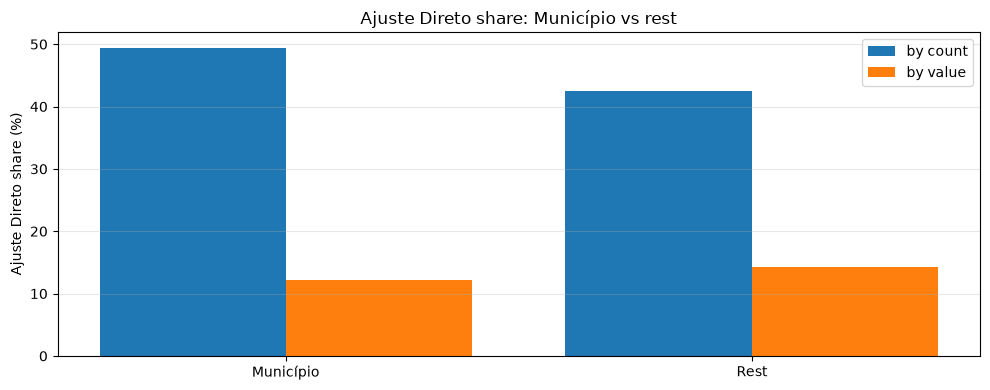

In [10]:
import numpy as np

def ad_shares(df: pl.DataFrame) -> tuple[float, float]:
    ad = df.filter(pl.col("is_ajuste_direto"))
    return ad.height / df.height * 100, ad["preco_contratual"].sum() / df["preco_contratual"].sum() * 100

shares = {"Município": ad_shares(mun), "Rest": ad_shares(rest)}
x = np.arange(2)
fig, ax = plt.subplots()
ax.bar(x - 0.2, [s[0] for s in shares.values()], 0.4, label="by count")
ax.bar(x + 0.2, [s[1] for s in shares.values()], 0.4, label="by value")
ax.set_xticks(x, list(shares))
ax.set_ylabel("Ajuste Direto share (%)")
ax.set_title("Ajuste Direto share: Município vs rest")
ax.legend()
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()


In [11]:
per_mun = (
    mun.group_by("adjudicante_key")
    .agg(
        pl.len().alias("n_contracts"),
        pl.col("is_ajuste_direto").mean().alias("ad_share"),
    )
    .filter(pl.col("n_contracts") >= 50)  # avoid small-denominator noise
    .join(canonical_names(mun, prefix="adjudicante"), on="adjudicante_key", how="left")
)
assert per_mun["ad_share"].is_between(0, 1).all()
print(f"{per_mun.height} municipalities with >= 50 contracts")
print("Highest AD share:")
display(per_mun.sort("ad_share", descending=True).head(15))
print("\nLowest AD share:")
display(per_mun.sort("ad_share").head(15))


303 municipalities with >= 50 contracts
Highest AD share:


adjudicante_key,n_contracts,ad_share,adjudicante_name
str,u32,f64,str
"""512073821""",179,0.960894,"""Município da Horta"""
"""512043701""",95,0.947368,"""Município de Vila Franca do Ca…"
"""512074410""",334,0.913174,"""Município de Lagoa (Açores)"""
"""512074089""",53,0.90566,"""Município de Calheta São Jorge"""
"""512044023""",138,0.862319,"""Município da Praia da Vitória"""
"""506659968""",164,0.768293,"""Município do Crato"""
"""500832935""",99,0.767677,"""Município de Cuba"""
"""506824942""",222,0.752252,"""Município de Sabrosa"""
"""512044040""",75,0.746667,"""Município de Angra do Heroísmo"""



Lowest AD share:


adjudicante_key,n_contracts,ad_share,adjudicante_name
str,u32,f64,str
"""512070946""",77,0.142857,"""Município da Madalena"""
"""505377802""",235,0.2,"""Município de Proença-a-Nova"""
"""506215547""",329,0.203647,"""Municipio de Bragança"""
"""505211696""",239,0.217573,"""Município de Arcos de Valdevez"""
"""512074143""",109,0.229358,"""Município das Lajes do Pico"""
"""501143718""",288,0.239583,"""Município de Portalegre"""
"""506770664""",236,0.25,"""Município de Vouzela"""
"""506874249""",438,0.253425,"""Município de Alcobaça"""
"""506874320""",534,0.254682,"""Município de Valpaços"""


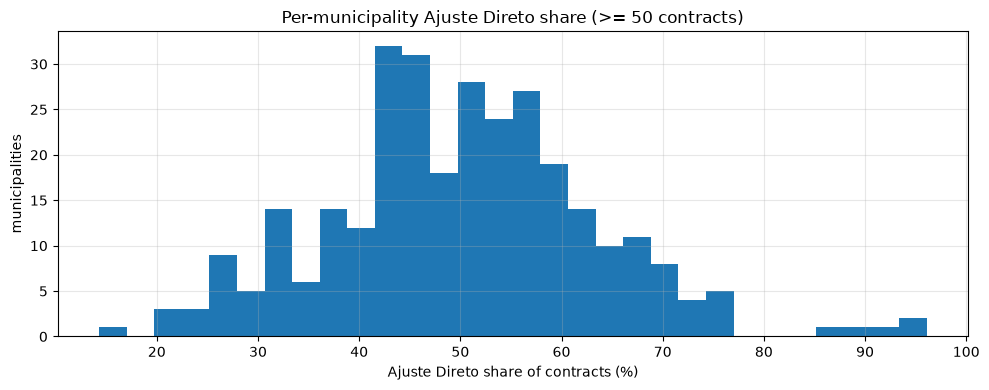

In [12]:
fig, ax = plt.subplots()
ax.hist(per_mun["ad_share"].to_numpy() * 100, bins=30)
ax.set_xlabel("Ajuste Direto share of contracts (%)")
ax.set_ylabel("municipalities")
ax.set_title("Per-municipality Ajuste Direto share (>= 50 contracts)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [13]:
(
    mun.group_by("is_ajuste_direto")
    .agg(
        pl.len().alias("n_contracts"),
        pl.col("preco_contratual").median().alias("median_value"),
        pl.col("preco_contratual").mean().alias("mean_value"),
        pl.col("preco_contratual").sum().alias("total_value"),
    )
    .sort("is_ajuste_direto")
)


is_ajuste_direto,n_contracts,median_value,mean_value,total_value
bool,u32,f64,f64,f64
false,47197,39000.0,157815.645498,7.4484e9
true,46134,12022.6,22437.736793,1.0351e9


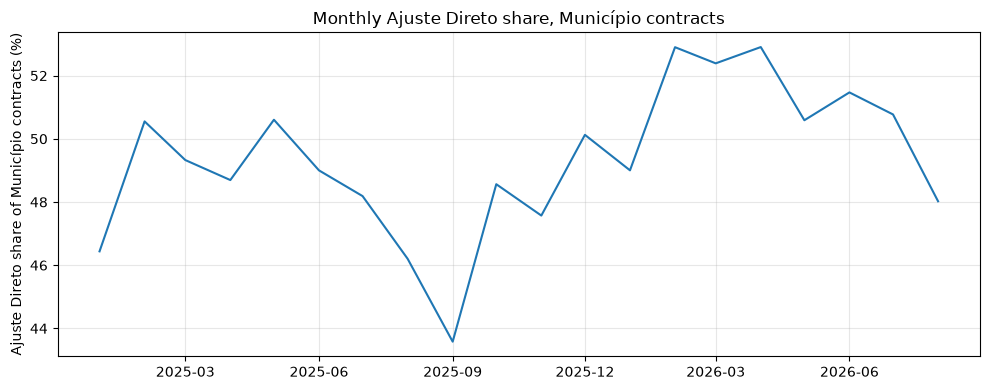

In [14]:
mm = (
    mun.filter(pl.col("data_celebracao").is_not_null())
    .with_columns(pl.col("data_celebracao").dt.truncate("1mo").alias("month"))
    .group_by("month")
    .agg((pl.col("is_ajuste_direto").mean() * 100).alias("ad_share"), pl.len().alias("n_contracts"))
    .sort("month")
)
fig, ax = plt.subplots()
ax.plot(mm["month"], mm["ad_share"])
ax.set_ylabel("Ajuste Direto share of Município contracts (%)")
ax.set_title("Monthly Ajuste Direto share, Município contracts")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Commentary and limitations

Direct award dominates municipal procurement by **count** (about half of contracts) but far less by **value**
(about an eighth): many small contracts go through Ajuste Direto while the large spend goes through
competitive procedures.

Limitations: 2025–2026 only (partial edge months); the Município rule may include false positives;
no per-contract legal-threshold validation.
Municipalities are keyed by NIPC (`adjudicante_key`), so the `>= 50` filter now counts each entity once
instead of once per name spelling.


Contracts with |value| below €10 are disregarded; `valor_por_dia` uses only 1–3650-day durations.